# Chapter 63: Demography, Poverty Traps, and Unified Growth

This notebook reruns four worked examples from the chapter: the cost of children when quantity and quality interact, the demographic dividend, a training threshold trap and the big push. Every example is invented, as in the book; the numbers are constructed teaching numbers, not historical data, and a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def quantity_quality_cost(n, q, a, b, d):
    """Child cost C = a n + b q + d n q with shadow prices P_n = a + d q and P_q = b + d n.

    quantity-quality-tradeoff-in-children (chapter 63): a 18, b 3, d 2 gives C(3, 20) = 234,
    P_n = 58, P_q = 9; C(2, 50) = 386, C(3, 50) = 504, C(5, 20) = 350, P_n(q = 50) = 118.
    """
    n, q = float(n), float(q)
    return {"cost": a * n + b * q + d * n * q, "quantity_part": a * n, "quality_part": b * q,
            "interaction": d * n * q, "P_n": a + d * q, "P_q": b + d * n}


def demographic_decomposition(yw, er, ws):
    """Output per resident Y/N = (Y/E)(E/W)(W/N).

    demographic-dividend (chapter 63): 50(0.70)(0.45) = 15.75; 50(0.70)(0.60) = 21;
    54(0.75)(0.60) = 24.30; 54(0.75)(0.45) = 18.225.
    """
    return float(yw) * float(er) * float(ws)


def threshold_payoff(n, threshold, r_low, r_high, c):
    """Threshold externality: each of n participants earns R - c, with R = r_high if n >= threshold.

    threshold-externality-poverty-trap (chapter 63): threshold 48,
    returns 7 and 15, cost 10 gives individual net 5 and group 48(5) = 240; at 47, 47(-3) = -141.
    """
    high = n >= threshold
    gross = r_high if high else r_low
    net = gross - c
    return {"above": high, "gross": gross, "net": net, "group": n * net}


def big_push_profit(m, base, spill, cost):
    """Big push: profit of one plant with m other plants operating, pi(m) = base + spill m - cost.

    big-push-coordination-failure (chapter 63): 105, 20, 150 gives
    pi(0) = -45, pi(1) = -25, pi(2) = -5, pi(3) = 15.
    """
    return base + spill * m - cost


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(quantity_quality_cost=quantity_quality_cost)


growth = SimpleNamespace(demographic_decomposition=demographic_decomposition)


games = SimpleNamespace(threshold_payoff=threshold_payoff, big_push_profit=big_push_profit)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'quantity-quality-tradeoff-in-children': {'a': 18,
                                           'b': 3,
                                           'd': 2,
                                           'resources': 420,
                                           'cost_3_20': 234,
                                           'P_n_20': 58,
                                           'P_q_3': 9,
                                           'cost_2_50': 386,
                                           'leftover_2_50': 34,
                                           'cost_3_50': 504,
                                           'P_n_50': 118,
                                           'cost_5_20': 350},
 'demographic-dividend': {'N': 1200,
                          'W0': 540,
                          'E0': 378,
                          'W1': 720,
                          'yw': 50,
                          'er': 0.7,
                          'ws0': 0.45,
                          'ws1': 0.6,
                          'y_base': 15.75,
                          'y_comp': 21,
                          'gain_pct': 33.3,
                          'yw2': 54,
                          'er2': 0.75,
                          'y_full': 24.3,
                          'y_old_share': 18.225,
                          'age_share_contribution': 6.075},
 'threshold-externality-poverty-trap': {'adults': 80,
                                        'c': 10,
                                        'r_low': 7,
                                        'r_high': 15,
                                        'threshold': 48,
                                        'net_low': -3,
                                        'net_high': 5,
                                        'group_48': 240,
                                        'group_47': -141},
 'big-push-coordination-failure': {'plants': 4,
                                   'cost': 150,
                                   'base': 105,
                                   'spill': 20,
                                   'pi': {0: -45, 1: -25, 2: -5, 3: 15},
                                   'aggregate': 60},
 'constructed': {'quantity-quality-tradeoff-in-children': {'P_q_2': 7},
                 'threshold-externality-poverty-trap': {'c': [8, 12], 'n': [0, 80]},
                 'big-push-coordination-failure': {'spill': [15, 25]}}}


def children_picture(n=2, q=50):
    bv = BV["quantity-quality-tradeoff-in-children"]
    a, b, d, budget = bv["a"], bv["b"], bv["d"], bv["resources"]
    r = choice.quantity_quality_cost(n, q, a, b, d)
    cost = r["cost"]
    left = budget - cost
    fits = cost <= budget
    fig, ax = new_figure()
    parts = [("a n", r["quantity_part"], "teal"), ("b q", r["quality_part"], "navy"),
             ("d n q", r["interaction"], "gold")]
    base = 0.0
    for name, val, col in parts:
        ax.bar([0], [val], bottom=[base], color=PALETTE[col], width=0.5)
        label(ax, 0.27, base + val / 2, f"{name} = {num(val, 0)}", col=col, dx=4, dy=0, va="center")
        base += val
    hline(ax, budget, f"resources {num(budget, 0)}", col="terracotta", x_frac=0.55)
    mark(ax, 0, cost, f"cost {num(cost, 0)}", col="ink", dx=-8, dy=6, ha="right")
    ax.set_xlim(-0.6, 1.4)
    ax.set_xticks([0], [f"n = {n}, q = {q}"])
    ax.set_ylim(0, 820)
    ax.set_xlabel("Bundle of children and investment per child")
    ax.set_ylabel("Child-related resources (units)")
    metrics = {"Cost C": num(cost, 0), "Left over from 420": num(left, 0) if fits else f"short by {num(-left, 0)}",
               "Shadow price of a child P_n": num(r["P_n"], 0), "Shadow price of quality P_q": num(r["P_q"], 0),
               "Affordable": "yes" if fits else "no"}
    calc = (f"{a}({n}) + {b}({q}) + {d}({n})({q}) = {num(r['quantity_part'], 0)} + {num(r['quality_part'], 0)} + "
            f"{num(r['interaction'], 0)} = {num(cost, 0)}")
    verdict = (f"which fits in 420 with {num(left, 0)} left over" if fits
               else f"which exceeds 420 by {num(-left, 0)}, so the bundle is not affordable")
    interp = (f"C = {calc}, {verdict}. Another child costs P_n = {a} + {d}({q}) = {num(r['P_n'], 0)} at this "
              f"standard, and one more unit of investment per child costs P_q = {b} + {d}({n}) = {num(r['P_q'], 0)}. "
              f"The interaction term d n q is why a higher standard makes each extra child dearer.")
    steps = [f"C = {calc}",
             (f"Left over = 420 - {num(cost, 0)} = {num(left, 0)}" if fits
              else f"Shortfall = {num(cost, 0)} - 420 = {num(-left, 0)}"),
             f"P_n = {a} + {d} x {q} = {num(r['P_n'], 0)}",
             f"P_q = {b} + {d} x {n} = {num(r['P_q'], 0)}"]
    alt = (f"A stacked bar for {n} children at investment {q}: parts {num(r['quantity_part'], 0)}, "
           f"{num(r['quality_part'], 0)} and {num(r['interaction'], 0)} sum to {num(cost, 0)}, against a resource "
           f"line at 420.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def dividend_picture(ws=0.60, er=0.70, yw=50):
    bv = BV["demographic-dividend"]
    base = growth.demographic_decomposition(bv["yw"], bv["er"], bv["ws0"])
    y = growth.demographic_decomposition(yw, er, ws)
    old_share = growth.demographic_decomposition(yw, er, bv["ws0"])
    age = y - old_share
    rise = (y - base) / base
    fig, ax = new_figure()
    names = ["Baseline", "This state"]
    vals = [base, y]
    ax.bar([0], [base], color=PALETTE["light"], width=0.55)
    ax.bar([1], [old_share], color=PALETTE["teal"], width=0.55)
    ax.bar([1], [age], bottom=[old_share], color=PALETTE["gold"], width=0.55)
    for x, v in zip([0, 1], vals):
        ax.annotate(num(v, 3 if abs(v * 100 - round(v * 100)) > 1e-9 else 2), (x, v), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=10.5, color=PALETTE["ink"])
    if age > 0:
        label(ax, 1.3, old_share + age / 2, f"age share +{num(age, 3)}", col="gold", dx=4, dy=0, va="center")
    label(ax, 1.3, old_share / 2, f"at share 0.45: {num(old_share, 3)}", col="teal", dx=4, dy=0, va="center")
    ax.set_xticks([0, 1], names)
    ax.set_xlim(-0.5, 2.4)
    ax.set_ylim(0, 30)
    ax.set_xlabel("Hypothetical country, population 1,200")
    ax.set_ylabel("Output per resident Y/N")
    metrics = {"Y/N": num(y, 3), "Baseline Y/N": num(base), "Change from baseline": pct(rise),
               "Y/N at the old 0.45 share": num(old_share, 3), "Age-share contribution": num(age, 3)}
    if abs(ws - bv["ws0"]) < 1e-12:
        split = ("The working-age share is still the old 0.45, so the age structure contributes "
                 f"{num(y, 3)} - {num(old_share, 3)} = {num(age, 3)}; any change from the baseline comes from "
                 "output per worker and the employment rate.")
    else:
        split = (f"With the same output per worker and employment rate but the old 0.45 share, Y/N would be "
                 f"{num(old_share, 3)}, so the age structure contributes "
                 f"{num(y, 3)} - {num(old_share, 3)} = {num(age, 3)}.")
    interp = (f"Y/N = {num(yw, 0)} x {num(er)} x {num(ws)} = {num(y, 3)}, against the baseline 50 x 0.70 x 0.45 = "
              f"{num(base)}, a change of {pct(rise)}. " + split)
    steps = [f"Y/N = {num(yw, 0)} x {num(er)} x {num(ws)} = {num(y, 3)}",
             f"Baseline = 50 x 0.70 x 0.45 = {num(base)}",
             f"Change = ({num(y, 3)} - {num(base)}) / {num(base)} = {pct(rise)}",
             f"At share 0.45: {num(yw, 0)} x {num(er)} x 0.45 = {num(old_share, 3)}",
             f"Age-share contribution = {num(y, 3)} - {num(old_share, 3)} = {num(age, 3)}"]
    alt = (f"Two bars: baseline output per resident {num(base)} and this state's {num(y, 3)}, split into the value at "
           f"the old 0.45 working-age share ({num(old_share, 3)}) and the age-share contribution ({num(age, 3)}).")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def threshold_picture(n=48, c=10):
    bv = BV["threshold-externality-poverty-trap"]
    T, lo, hi = bv["threshold"], bv["r_low"], bv["r_high"]
    r = games.threshold_payoff(n, T, lo, hi, c)
    fig, ax = new_figure()
    xs = np.arange(0, 81)
    nets = [games.threshold_payoff(x, T, lo, hi, c)["net"] for x in xs]
    ax.step(xs, nets, where="post", color=PALETTE["teal"], linewidth=2.2)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    vline(ax, T, f"threshold {T}", col="terracotta", y_frac=0.97, ha="right")
    shown = n if n > 0 else 1
    net_shown = games.threshold_payoff(shown, T, lo, hi, c)["net"]
    right = n > 60
    tag = "lone trainee" if n == 0 else f"n = {n}"
    mark(ax, shown, net_shown, f"{tag}: net {num(net_shown, 0)}", col="ink", dx=-8 if right else 8, dy=8,
         ha="right" if right else "left")
    ax.set_xlim(0, 82)
    ax.set_ylim(-8, 11)
    ax.set_xlabel("Adults who train")
    ax.set_ylabel("Net return per trainee (R - c)")
    if n == 0:
        metrics = {"Net return per trainee": f"{num(net_shown, 0)} for a lone trainee", "Group payoff": "0",
                   "Employer enters": "no"}
        interp = (f"With no one committed, an adult who trains alone earns {lo} - {c} = {num(net_shown, 0)}, so "
                  f"declining is rational and zero enrollment confirms itself. The group payoff is 0.")
        steps = [f"Participation 1 is below {T}, so R = {lo}",
                 f"Lone trainee: {lo} - {c} = {num(net_shown, 0)}", "Nobody trains, so the group payoff is 0"]
    else:
        R = hi if r["above"] else lo
        where = "at or above" if r["above"] else "below"
        metrics = {"Net return per trainee": num(r["net"], 0), "Group payoff": num(r["group"], 0),
                   "Employer enters": "yes" if r["above"] else "no"}
        interp = (f"{n} trainees is {where} the threshold of {T}, so the gross return is {R} and each trainee nets "
                  f"{R} - {c} = {num(r['net'], 0)}. The group payoff is {n}({R} - {c}) = {num(r['group'], 0)}.")
        steps = [f"{n} is {where} {T}, so R = {R}",
                 f"Net per trainee = {R} - {c} = {num(r['net'], 0)}",
                 f"Group payoff = {n} x {signed(r['net'], 0)} = {num(r['group'], 0)}"]
    alt = (f"Net return per trainee as a step: {num(lo - c, 0)} below {T} adults and {num(hi - c, 0)} at or above. "
           + (f"The marked point is participation {n}." if n else
            "Nobody is committed, so the marked point is a lone trainee at participation 1."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def push_picture(m=3, spill=20):
    bv = BV["big-push-coordination-failure"]
    base, cost = bv["base"], bv["cost"]
    pis = [games.big_push_profit(k, base, spill, cost) for k in range(4)]
    pi = pis[m]
    fig, ax = new_figure()
    cols = [PALETTE["gold"] if k == m else PALETTE["teal"] for k in range(4)]
    ax.bar(range(4), pis, color=cols, width=0.6)
    for k, v in enumerate(pis):
        ax.annotate(num(v, 0), (k, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=10.5, color=PALETTE["ink"])
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_xticks(range(4), ["0", "1", "2", "3"])
    ax.set_ylim(-70, 50)
    ax.set_xlabel("Other plants operating, m")
    ax.set_ylabel("Profit of one plant, pi(m)")
    coalition = "holds" if pis[2] > 0 else ("breaks even" if pis[2] == 0 else "unravels")
    metrics = {"pi(m)": num(pi, 0), "pi(0), lone plant": num(pis[0], 0), "pi(2), three-plant coalition": num(pis[2], 0),
               "Aggregate profit, all four": num(4 * pis[3], 0), "Three-plant coalition": coalition}
    if pis[3] > 0:
        full = "so full entry is also an equilibrium"
    elif pis[3] == 0:
        full = "a tie with staying out, so full entry is only weakly an equilibrium"
    else:
        full = "so full entry is not an equilibrium"
    interp = (f"pi({m}) = {base} + {spill}({m}) - {cost} = {num(pi, 0)}. A lone plant earns pi(0) = {num(pis[0], 0)}, "
              f"so zero entry is an equilibrium; with all four in, each earns pi(3) = {num(pis[3], 0)}, {full}, and "
              f"aggregate profit is 4({num(pis[3], 0)}) = {num(4 * pis[3], 0)}. A three-plant coalition gives each member "
              f"pi(2) = {num(pis[2], 0)}, so it {coalition}.")
    steps = [f"pi({m}) = {base} + {spill} x {m} - {cost} = {num(pi, 0)}",
             f"pi(0) = {base} - {cost} = {num(pis[0], 0)}",
             f"pi(2) = {base} + {num(2 * spill, 0)} - {cost} = {num(pis[2], 0)}",
             f"pi(3) = {base} + {num(3 * spill, 0)} - {cost} = {num(pis[3], 0)}",
             f"Aggregate = 4 x {num(pis[3], 0)} = {num(4 * pis[3], 0)}"]
    alt = (f"Bars of one plant's profit for 0 to 3 other plants with spillover {spill}: "
           f"{', '.join(num(v, 0) for v in pis)}. The bar for m = {m} is highlighted"
           + (" (it has zero height)." if pi == 0 else "."))
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Quantity-quality tradeoff: fewer children, more schooling

Child-related cost is $C=an+bq+dnq$ with $a=18$, $b=3$, $d=2$ and resources 420.

$$18(3)+3(20)+2(3)(20)=54+60+120=234.$$

The shadow price of a child is $P_n=a+dq$: $P_n=18+2(20)=58$ at $q=20$ and $P_n'=18+2(50)=118$ at $q=50$.

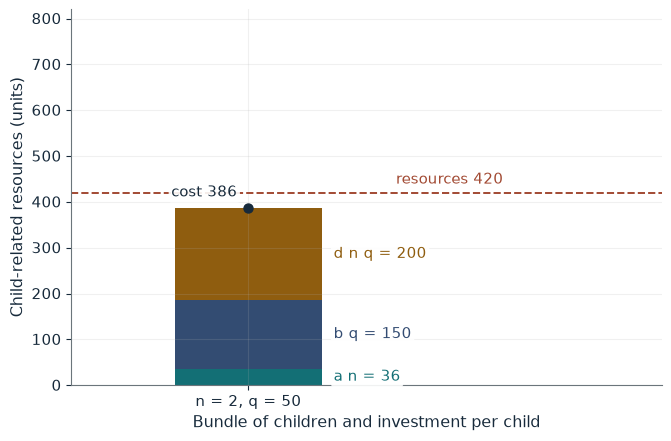

Cost C                       386
Left over from 420           34
Shadow price of a child P_n  118
Shadow price of quality P_q  7
Affordable                   yes

Worked steps:
  1. C = 18(2) + 3(50) + 2(2)(50) = 36 + 150 + 200 = 386
  2. Left over = 420 - 386 = 34
  3. P_n = 18 + 2 x 50 = 118
  4. P_q = 3 + 2 x 2 = 7

C = 18(2) + 3(50) + 2(2)(50) = 36 + 150 + 200 = 386, which fits in 420 with 34 left over. Another child costs P_n = 18 + 2(50) = 118 at this standard, and one more unit of investment per child costs P_q = 3 + 2(2) = 7. The interaction term d n q is why a higher standard makes each extra child dearer.


In [2]:
show(children_picture(n=2, q=50))

Change one input, `n`, and hold the others at the book's values:

In [3]:
sweep(children_picture, 'n', [2, 3, 5], {'q': 50}, ['Cost C', 'Affordable', 'Shadow price of quality P_q'])

n | Cost C | Affordable | Shadow price of quality P_q
2 | 386 | yes | 7
3 | 504 | no | 9
5 | 740 | no | 13


Two children at $q=50$ cost 386 and leave 34. Three would cost 504, above 420, although five children at the old standard ($q=20$) cost only 350. The higher standard more than doubles the marginal cost of a child, from 58 to 118.

## 2. Demographic dividend: a larger working-age share

Output per resident is the product of output per worker, the employment rate and the working-age share.

$$\frac{Y}{N}=50(0.70)(0.45)=15.75.$$

$$\frac{Y}{N}=50(0.70)(0.60)=21.$$

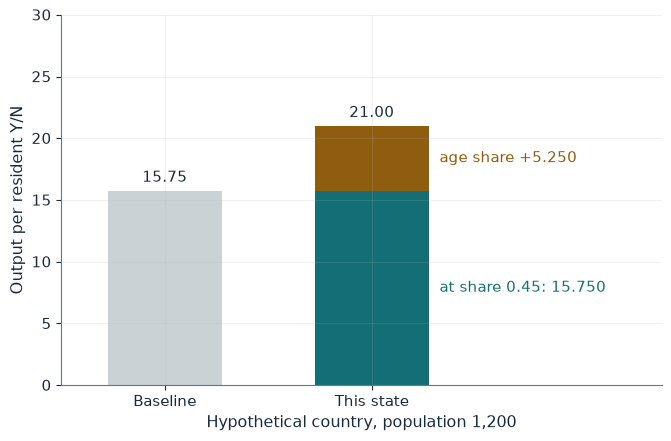

Y/N                        21.000
Baseline Y/N               15.75
Change from baseline       33.3%
Y/N at the old 0.45 share  15.750
Age-share contribution     5.250

Worked steps:
  1. Y/N = 50 x 0.70 x 0.60 = 21.000
  2. Baseline = 50 x 0.70 x 0.45 = 15.75
  3. Change = (21.000 - 15.75) / 15.75 = 33.3%
  4. At share 0.45: 50 x 0.70 x 0.45 = 15.750
  5. Age-share contribution = 21.000 - 15.750 = 5.250

Y/N = 50 x 0.70 x 0.60 = 21.000, against the baseline 50 x 0.70 x 0.45 = 15.75, a change of 33.3%. With the same output per worker and employment rate but the old 0.45 share, Y/N would be 15.750, so the age structure contributes 21.000 - 15.750 = 5.250.


In [4]:
show(dividend_picture(ws=0.60, er=0.70, yw=50))

Change one input, `ws`, and hold the others at the book's values:

In [5]:
sweep(dividend_picture, 'ws', [0.45, 0.6], {'er': 0.75, 'yw': 54}, ['Y/N', 'Age-share contribution'])

ws | Y/N | Age-share contribution
0.45 | 18.225 | 0.000
0.6 | 24.300 | 6.075


Composition alone raises Y/N by one third, from 15.75 to 21. With employment 0.75 and output per worker 54, the age share contributes 24.30 - 18.225 = 6.075. Population is held at 1,200, so this is a counterfactual, not a forecast.

## 3. Threshold-externality poverty trap: train if enough others train

A trainee earns 7 below 48 participants and 15 at or above, at cost 10.

$$48(15-10)=240.$$

$$47(7-10)=-141.$$

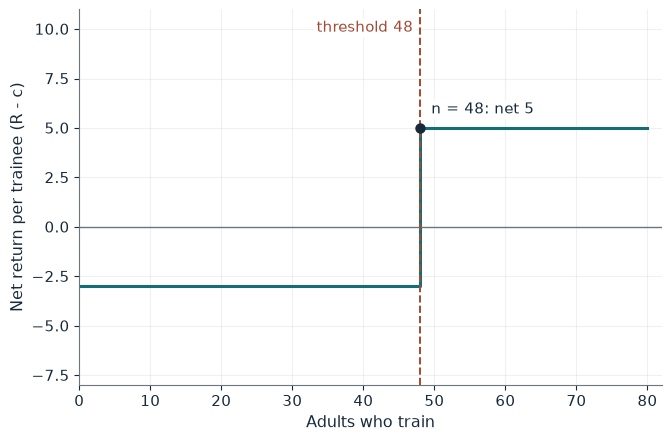

Net return per trainee  5
Group payoff            240
Employer enters         yes

Worked steps:
  1. 48 is at or above 48, so R = 15
  2. Net per trainee = 15 - 10 = 5
  3. Group payoff = 48 x 5 = 240

48 trainees is at or above the threshold of 48, so the gross return is 15 and each trainee nets 15 - 10 = 5. The group payoff is 48(15 - 10) = 240.


In [6]:
show(threshold_picture(n=48, c=10))

Change one input, `n`, and hold the others at the book's values:

In [7]:
sweep(threshold_picture, 'n', [0, 47, 48, 80], {'c': 10}, ['Net return per trainee', 'Group payoff'])

n | Net return per trainee | Group payoff
0 | -3 for a lone trainee | 0
47 | -3 | -141
48 | 5 | 240
80 | 5 | 400


One commitment separates a group payoff of -141 from +240. Both zero enrollment and wide enrollment are equilibria under the same returns.

## 4. Big-push coordination failure

Each of four plants has cost 150 and base revenue 105, and every other operating plant adds 20.

$$\pi(m)=105+20m-150.$$

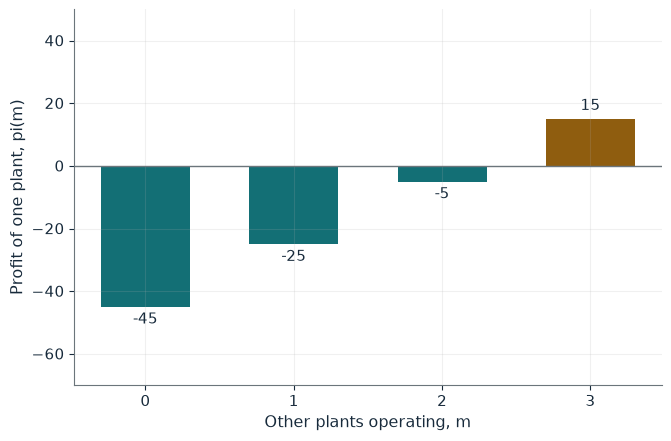

pi(m)                         15
pi(0), lone plant             -45
pi(2), three-plant coalition  -5
Aggregate profit, all four    60
Three-plant coalition         unravels

Worked steps:
  1. pi(3) = 105 + 20 x 3 - 150 = 15
  2. pi(0) = 105 - 150 = -45
  3. pi(2) = 105 + 40 - 150 = -5
  4. pi(3) = 105 + 60 - 150 = 15
  5. Aggregate = 4 x 15 = 60

pi(3) = 105 + 20(3) - 150 = 15. A lone plant earns pi(0) = -45, so zero entry is an equilibrium; with all four in, each earns pi(3) = 15, so full entry is also an equilibrium, and aggregate profit is 4(15) = 60. A three-plant coalition gives each member pi(2) = -5, so it unravels.


In [8]:
show(push_picture(m=3, spill=20))

Change one input, `spill`, and hold the others at the book's values:

In [9]:
sweep(push_picture, 'spill', [15, 20, 25], {'m': 2}, ['pi(m)', 'Three-plant coalition'])

spill | pi(m) | Three-plant coalition
15 | -15 | unravels
20 | -5 | unravels
25 | 5 | holds


With spillover 20 a lone plant loses 45 and a three-plant coalition loses 5 per member, but all four together earn 15 each, 60 in total. At spillover 25 the three-plant coalition earns 5.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

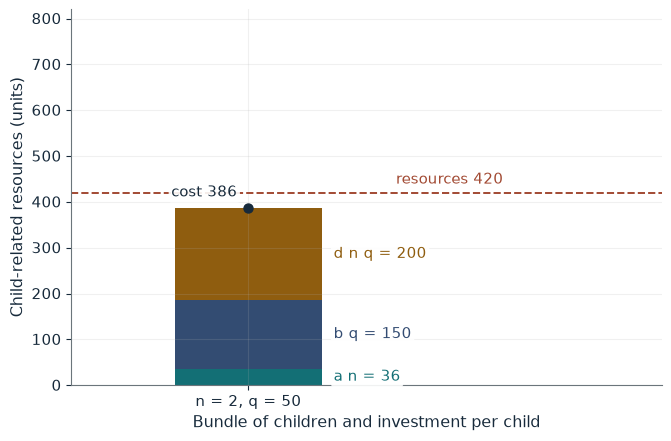

Cost C                       386
Left over from 420           34
Shadow price of a child P_n  118
Shadow price of quality P_q  7
Affordable                   yes

Worked steps:
  1. C = 18(2) + 3(50) + 2(2)(50) = 36 + 150 + 200 = 386
  2. Left over = 420 - 386 = 34
  3. P_n = 18 + 2 x 50 = 118
  4. P_q = 3 + 2 x 2 = 7

C = 18(2) + 3(50) + 2(2)(50) = 36 + 150 + 200 = 386, which fits in 420 with 34 left over. Another child costs P_n = 18 + 2(50) = 118 at this standard, and one more unit of investment per child costs P_q = 3 + 2(2) = 7. The interaction term d n q is why a higher standard makes each extra child dearer.


In [10]:
show(children_picture(n=2, q=50))

## Practice

**1.** Is three children at $q=50$ affordable with 420?

<details><summary>Answer</summary>

18(3) + 3(50) + 2(3)(50) = 54 + 150 + 300 = 504 > 420, so no.

</details>

**2.** With employment 0.75 and output per worker 54, what is the age-share contribution?

<details><summary>Answer</summary>

54(0.75)(0.60) = 24.30 and 54(0.75)(0.45) = 18.225, so 24.30 - 18.225 = 6.075.

</details>

**3.** With spillover 25, does a three-plant coalition survive?

<details><summary>Answer</summary>

pi(2) = 105 + 50 - 150 = 5 > 0, so yes.

</details>